# 02 · Exploration, correlations and feature engineering

Workstream 2. The logic lives in `src/features.py`; this notebook narrates it.
**Only development years 2009–2013 are explored.** The 2014 test labels are never looked at,
and 2015 (incomplete follow-up) is dropped. Figures go to `figures/eda/`, tables to
`results/features/`. Decisions are logged in `docs/decisions/02_features.md`.

Reminder: everything below is correlation in observational data. A feature that is associated
with breakouts is useful for *ranking* players; it does not show that changing it would cause one.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.common import (A_FIGURES, A_TABLES, COLORS, DEV_YEARS, PLAYER, SKILLS, TARGET,
                        YOUTH_MAX_AGE, cohort, diverging_cmap, save, set_style)
from src import eda as E
from src import features as F

set_style()
pd.set_option("display.width", 140, "display.max_columns", 30, "display.precision", 3)

table = F.load_feature_table(include_incomplete=True, save=True)   # also saved to data/
dev = E.add_bands(table[table.year.isin(DEV_YEARS)])                 # 2014-2015 rows are not used
young = cohort(dev, "young")
print(f"feature table (2009–2015): {table.shape}; development rows: {len(dev):,} "
      f"({dev[PLAYER].nunique():,} players); young (age <= {YOUTH_MAX_AGE}): {len(young):,}")

feature table (2009–2015): (25502, 79); development rows: 18,002 (7,200 players); young (age <= 24): 6,800


## 1. Outcome: rating change and breakout rate by year

The label is `change ≥ annual median + 3`; the median change is 0 in every year, so a breakout is
a rise of at least 3 overall points between the two annual snapshots.

In [2]:
by_year = pd.concat([
    dev.groupby("year").agg(rows=(TARGET, "size"), breakouts=(TARGET, "sum"),
                            rate=(TARGET, "mean"), median_change=("change", "median"),
                            mean_change=("change", "mean"), sd_change=("change", "std"))
       .assign(cohort="all"),
    young.groupby("year").agg(rows=(TARGET, "size"), breakouts=(TARGET, "sum"),
                              rate=(TARGET, "mean"), median_change=("change", "median"),
                              mean_change=("change", "mean"), sd_change=("change", "std"))
       .assign(cohort="young"),
]).reset_index()
save(by_year, A_TABLES, "outcome_by_year")
by_year

,year,rows,breakouts,rate,median_change,mean_change,sd_change,cohort
0,2009,3317,853,0.257,0.0,1.017,3.829,all
1,2010,3535,595,0.168,0.0,0.207,3.323,all
2,2011,3618,729,0.201,0.0,0.507,3.367,all
3,2012,3741,682,0.182,0.0,0.308,2.949,all
4,2013,3791,430,0.113,0.0,0.007,2.372,all
5,2009,1198,507,0.423,2.0,2.632,4.456,young
6,2010,1330,403,0.303,1.0,1.669,3.775,young
7,2011,1403,479,0.341,1.0,1.706,3.783,young
8,2012,1449,422,0.291,1.0,1.327,3.174,young
9,2013,1420,297,0.209,0.0,0.901,2.610,young


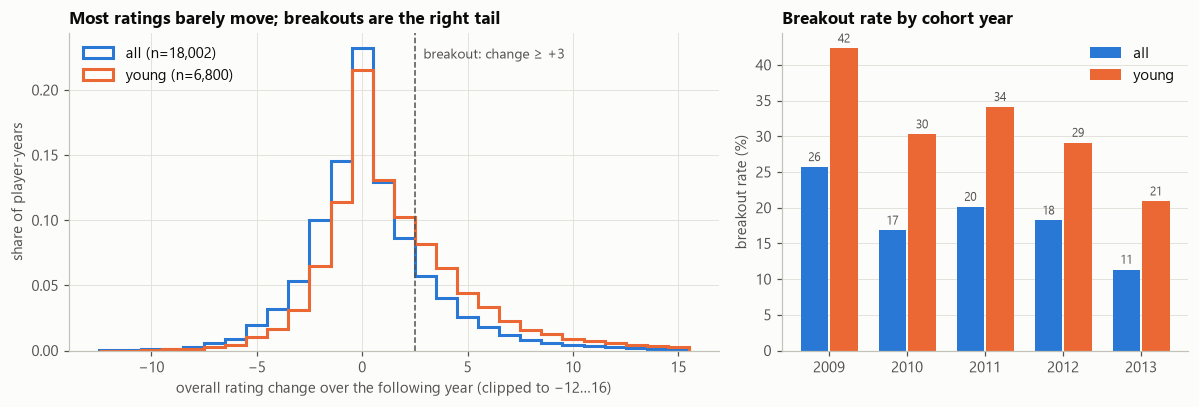

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
bins = np.arange(-12.5, 16.5, 1)
for name, d in [("all", dev), ("young", young)]:
    ax.hist(d.change.clip(-12, 16), bins=bins, density=True, histtype="step", linewidth=2,
            color=COLORS[name], label=f"{name} (n={len(d):,})")
ax.axvline(2.5, color=COLORS["ink2"], linestyle="--", linewidth=1)
ax.text(2.9, ax.get_ylim()[1] * 0.92, "breakout: change ≥ +3", fontsize=9, color=COLORS["ink2"])
ax.set_xlabel("overall rating change over the following year (clipped to −12…16)")
ax.set_ylabel("share of player-years")
ax.set_title("Most ratings barely move; breakouts are the right tail")
ax.legend()

ax = axes[1]
w = 0.38
for i, name in enumerate(["all", "young"]):
    d = by_year[by_year.cohort == name]
    x = np.arange(len(d)) + (i - 0.5) * w
    ax.bar(x, 100 * d.rate, width=w * 0.92, color=COLORS[name], label=name)
    for xx, r in zip(x, d.rate):
        ax.text(xx, 100 * r + 0.8, f"{100 * r:.0f}", ha="center", fontsize=8, color=COLORS["ink2"])
ax.set_xticks(np.arange(len(DEV_YEARS)), DEV_YEARS)
ax.set_ylabel("breakout rate (%)")
ax.set_title("Breakout rate by cohort year")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, A_FIGURES, "01_change_distribution_and_rate_by_year");

The rating change is concentrated at 0–2 points with a long right tail. The breakout rate falls
from about a quarter of player-years in 2009 to about a tenth in 2013 (and the young cohort is
roughly twice as likely to break out every year). Because prevalence drifts, every metric is
computed within a year and compared against that year's random baseline.

## 2. Breakout rate by age, rating band, league and position (all vs young)

In [4]:
rate_tables = {}
for field in ["age_band", "rating_band", "league", "position"]:
    t = pd.concat([E.rate_table(d, field).assign(cohort=name)
                   for name, d in [("all", dev), ("young", young)]])
    rate_tables[field] = t
    save(t.rename(columns={field: "group"}).assign(variable=field)
                 [["variable", "group", "cohort", "rows", "breakouts", "rate"]], A_TABLES, f"breakout_rate_by_{field}")
rate_tables["position"]

,position,rows,breakouts,rate,cohort
0,Defender,5813,980,0.169,all
1,Forward,3011,536,0.178,all
2,Goalkeeper,1489,262,0.176,all
3,Midfielder,6881,1249,0.182,all
4,Unknown,808,262,0.324,all
0,Defender,2047,608,0.297,young
1,Forward,1253,366,0.292,young
2,Goalkeeper,365,133,0.364,young
3,Midfielder,2837,865,0.305,young
4,Unknown,298,136,0.456,young


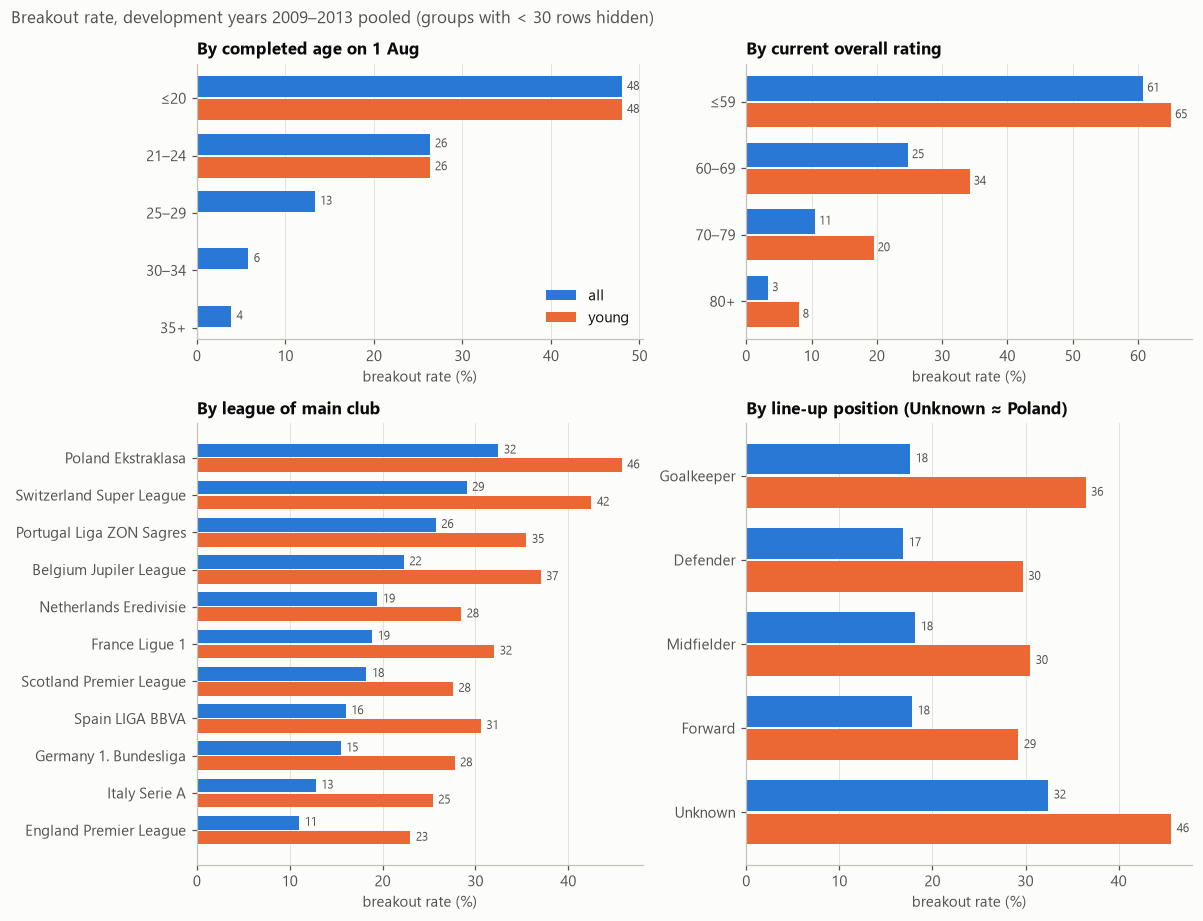

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), gridspec_kw={"height_ratios": [1, 1.6]})
orders = {
    "age_band": list(E.AGE_BANDS[1]), "rating_band": list(E.RATING_BANDS[1]),
    "league": list(rate_tables["league"].query("cohort == 'all'").sort_values("rate", ascending=False).league),
    "position": ["Goalkeeper", "Defender", "Midfielder", "Forward", "Unknown"],
}
titles = {"age_band": "By completed age on 1 Aug", "rating_band": "By current overall rating",
          "league": "By league of main club", "position": "By line-up position (Unknown ≈ Poland)"}
for ax, field in zip(axes.ravel(), ["age_band", "rating_band", "league", "position"]):
    t = rate_tables[field]
    E.plot_rate_bars(ax, {c: t[t.cohort == c] for c in ["all", "young"]}, field,
                     order=orders[field], title=titles[field])
axes[0, 0].legend(loc="lower right")
fig.suptitle("Breakout rate, development years 2009–2013 pooled (groups with < 30 rows hidden)",
             x=0.01, ha="left", fontsize=11, color=COLORS["ink2"])
fig.tight_layout()
save(fig, A_FIGURES, "02_breakout_rate_by_group");

**Confound: unknown position is (almost) Poland.** 801 of the 808 development rows without a
line-up position are in the Polish league, where line-up pitch coordinates are missing. Poland also
has the highest breakout rate, so the high "Unknown" rate is a league effect, not a position effect.
Within known positions the rates are similar. The one-hot `position=Unknown` column will behave like
a second Poland indicator; we keep it (it is honest about missingness) but do not interpret it.

In [6]:
dev_pos = dev.assign(pos=dev.position.fillna("Unknown"), poland=dev.league.str.startswith("Poland"))
confound = (dev_pos.groupby(["poland", "pos"])[TARGET].agg(rows="size", rate="mean")
            .reset_index().replace({"poland": {True: "Poland", False: "other leagues"}}))
save(confound, A_TABLES, "position_unknown_poland_confound")
confound

,poland,pos,rows,rate
0,other leagues,Defender,5812,0.169
1,other leagues,Forward,3011,0.178
2,other leagues,Goalkeeper,1489,0.176
3,other leagues,Midfielder,6879,0.182
4,other leagues,Unknown,7,0.143
5,Poland,Defender,1,0.000
6,Poland,Midfielder,2,0.000
7,Poland,Unknown,801,0.326


## 3. EA potential gap versus age (the circularity question)

EA's potential is a subjective EA judgement and our label is also EA's rating. Much of the gap is
simply age: EA gives young players room to grow. Below: how the gap falls with age, how much of its
variance age explains, and whether the gap still ranks players *within* an age.

In [7]:
gap_age = pd.DataFrame([E.potential_gap_vs_age(d) | {"cohort": name}
                        for name, d in [("all", dev), ("young", young)]])
save(gap_age, A_TABLES, "potential_gap_vs_age")

within_age = (dev.groupby("age_band", observed=True)
              .apply(lambda g: pd.Series({"rows": len(g), "breakout_rate": g[TARGET].mean(),
                                          "mean_gap": g.potential_gap.mean(),
                                          "spearman_gap_breakout": g.potential_gap.corr(g[TARGET], method="spearman")}))
              .reset_index())
save(within_age, A_TABLES, "potential_gap_within_age_band")
display(gap_age.round(3)); within_age.round(3)

,rows,r2_gap_on_age,corr_gap_age,auc_gap,auc_minus_age,auc_age_adjusted_gap,cohort
0,18002,0.411,-0.585,0.705,0.722,0.584,all
1,6800,0.255,-0.506,0.644,0.638,0.589,young


,age_band,rows,breakout_rate,mean_gap,spearman_gap_breakout
0,≤20,1475.0,0.480,11.045,0.199
1,21–24,5325.0,0.263,7.163,0.169
2,25–29,7180.0,0.133,4.108,0.145
3,30–34,3559.0,0.058,2.599,0.049
4,35+,463.0,0.039,3.106,0.022


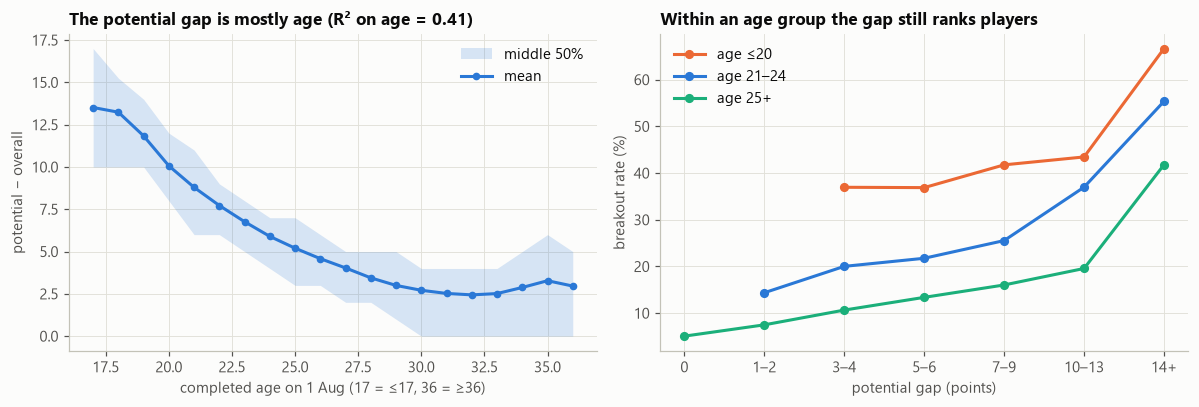

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
a = dev.assign(age_c=dev.age.clip(17, 36))
s = a.groupby("age_c").potential_gap.agg(["mean", lambda x: x.quantile(.25), lambda x: x.quantile(.75)])
s.columns = ["mean", "q25", "q75"]
ax.fill_between(s.index, s.q25, s.q75, color=COLORS["all"], alpha=0.18, linewidth=0, label="middle 50%")
ax.plot(s.index, s["mean"], color=COLORS["all"], linewidth=2, marker="o", markersize=4, label="mean")
ax.set_xlabel("completed age on 1 Aug (17 = ≤17, 36 = ≥36)")
ax.set_ylabel("potential − overall")
r2 = gap_age.set_index("cohort").loc["all", "r2_gap_on_age"]
ax.set_title(f"The potential gap is mostly age (R² on age = {r2:.2f})")
ax.legend()

ax = axes[1]
a["gap_bin"] = pd.cut(a.potential_gap, [-1, 0, 2, 4, 6, 9, 13, 40], labels=["0", "1–2", "3–4", "5–6", "7–9", "10–13", "14+"])
for name, band in [("≤20", ["≤20"]), ("21–24", ["21–24"]), ("25+", ["25–29", "30–34", "35+"])]:
    g = (a[a.age_band.isin(band)].groupby("gap_bin", observed=False)[TARGET].agg(["mean", "size"])
         .reindex(a.gap_bin.cat.categories))
    g.loc[g["size"] < 40, "mean"] = np.nan
    color = {"≤20": COLORS["young"], "21–24": COLORS["all"], "25+": COLORS["third"]}[name]
    ax.plot(np.arange(len(g)), 100 * g["mean"], marker="o", markersize=5, linewidth=2, color=color, label=f"age {name}")
ax.set_xticks(np.arange(len(a.gap_bin.cat.categories)), a.gap_bin.cat.categories)
ax.set_xlabel("potential gap (points)")
ax.set_ylabel("breakout rate (%)")
ax.set_title("Within an age group the gap still ranks players")
ax.legend()
fig.tight_layout()
save(fig, A_FIGURES, "03_potential_gap_vs_age");

## 4. Engineered features

All engineered features use only data dated before the row's 1 August cut-off (`src/features.py`):

| feature | definition | group |
|---|---|---|
| `rating_change_prev_year` | current overall − latest overall in [cut-off−2y, cut-off−1y) | rating history |
| `has_prev_rating` | 1 if that earlier rating exists | rating history |
| `rating_change_in_window` | current overall − earliest overall in the current 12-month window | rating history |
| `potential_change_prev_year` | same as momentum, for potential | potential history |
| `height_cm`, `weight_kg` | `Player` table (static, lb → kg) | player |
| `left_footed` | EA preferred foot on the current rating record | player |
| `attacking_work_rate_ord`, `defensive_work_rate_ord` | low/medium/high → 0/1/2; other codes → missing | player |
| `prev_starts`, `starts_change`, `has_prev_season` | starts in the previous season and the change | match history |
| `team_mean_rating`, `team_rating_rank_pct` | main club's mean current rating over all rated starters; player's percentile within it | match history |
| `club_lineup_coverage` | from the cleaned table (workstream 1): share of the club's line-up slots with a player id | match history (data quality) |
| `n_rating_updates_1y`, `rating_age_days` | number of rating records in the last year; days since the current rating | **built but excluded** |

Rating history is computed after removing isolated rating spikes with the same rule as the
cleaning step, but using only ratings dated before the cut-off. Missing values. `has_prev_rating = 0`
for 13% of rows (players new to the EA data); `prev_starts`
is missing for all 2009 rows because season 2007/08 is not in the database (`has_prev_season = 0`).
A player who did not start in the previous season gets `prev_starts = 0`. Work rates are missing
for 16% of 2009 rows (messy codes such as `norm`, `_0`, digits), under 1% later.

In [9]:
eng = [c for c in F.ENGINEERED] + ["club_lineup_coverage", "league_match_coverage"]
miss = (dev.groupby("year")[eng].apply(lambda d: d.isna().mean()).T.round(3))
save(miss.reset_index().rename(columns={"index": "feature"}), A_TABLES, "engineered_missing_share_by_year")
miss

year,2009,2010,2011,2012,2013
rating_change_prev_year,0.160,0.117,0.136,0.126,0.122
has_prev_rating,0.000,0.000,0.000,0.000,0.000
rating_change_in_window,0.000,0.000,0.000,0.000,0.000
rating_age_days,0.000,0.000,0.000,0.000,0.000
n_rating_updates_1y,0.000,0.000,0.000,0.000,0.000
potential_change_prev_year,0.160,0.117,0.136,0.126,0.122
height_cm,0.000,0.000,0.000,0.000,0.000
weight_kg,0.000,0.000,0.000,0.000,0.000
left_footed,0.000,0.000,0.000,0.000,0.000
attacking_work_rate_ord,0.158,0.096,0.008,0.005,0.006


In [10]:
numeric_candidates = ["overall_rating", "potential", "potential_gap", "age_years",
                      *[c for c in eng], "starts", "start_share", "club_ppg", "rating_vs_teammates"]
uni = {name: E.univariate_scores(d, numeric_candidates).assign(cohort=name)
       for name, d in [("all", dev), ("young", young)]}
uni_all = pd.concat(uni.values())
save(uni_all, A_TABLES, "univariate_association")
# within-year Spearman correlation: is the association stable across years?
stab = (dev.groupby("year")
        .apply(lambda g: pd.Series({c: g[c].corr(g[TARGET], method="spearman") for c in numeric_candidates}))
        .T.round(3))
save(stab.reset_index().rename(columns={"index": "feature"}), A_TABLES, "spearman_by_year")
uni["all"].merge(uni["young"][["feature", "auc"]], on="feature", suffixes=("_all", "_young")) \
    .sort_values("auc_oriented", ascending=False).round(3)

D:\PYTHON\Lib\site-packages\pandas\core\nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,feature,nonmissing_share,pearson_r,spearman_rho,auc_all,auc_oriented,cohort,auc_young
0,overall_rating,1.000,-0.344,-0.316,0.264,0.736,all,0.298
3,age_years,1.000,-0.292,-0.297,0.278,0.722,all,0.362
25,rating_vs_teammates,1.000,-0.343,-0.294,0.280,0.720,all,0.302
19,team_rating_rank_pct,1.000,-0.283,-0.281,0.290,0.710,all,0.314
2,potential_gap,1.000,0.305,0.275,0.705,0.705,all,0.644
15,prev_starts,0.816,-0.201,-0.212,0.338,0.662,all,0.374
16,starts_change,0.816,0.158,0.164,0.628,0.628,all,0.596
1,potential,1.000,-0.176,-0.160,0.380,0.620,all,0.372
18,team_mean_rating,1.000,-0.164,-0.155,0.384,0.616,all,0.423
5,has_prev_rating,1.000,-0.225,-0.225,0.401,0.599,all,0.406


In [11]:
stab

year,2009,2010,2011,2012,2013
overall_rating,-0.393,-0.355,-0.303,-0.280,-0.251
potential,-0.260,-0.221,-0.176,-0.134,-0.067
potential_gap,0.256,0.247,0.254,0.264,0.290
age_years,-0.329,-0.313,-0.324,-0.271,-0.265
rating_change_prev_year,0.067,0.108,0.135,0.070,0.034
has_prev_rating,-0.295,-0.192,-0.232,-0.172,-0.209
rating_change_in_window,0.093,0.091,0.094,0.091,0.055
rating_age_days,0.063,0.065,0.054,-0.007,-0.002
n_rating_updates_1y,-0.095,-0.119,-0.102,-0.048,0.015
potential_change_prev_year,0.046,0.039,0.060,0.081,0.035


`n_rating_updates_1y` and `rating_age_days` look useful pooled, but within a year their association
fades (`rating_age_days`) or flips sign (`n_rating_updates_1y`) by 2012–2013. In 2013 EA moved from
two rating updates a year to near-monthly updates, so these columns mostly encode the year and the
rating calendar, not the player; `rating_age_days` is also part of the outcome horizon. We keep them
in the table but out of every feature set.

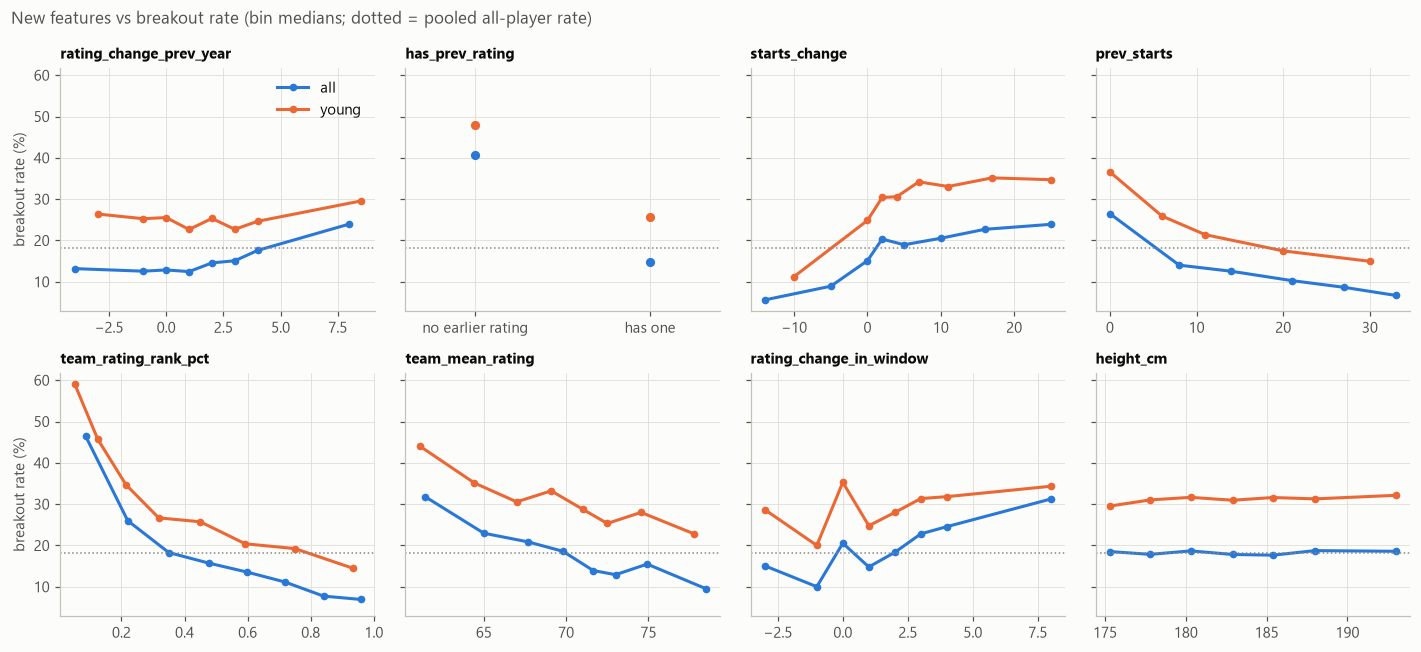

In [12]:
show = ["rating_change_prev_year", "has_prev_rating", "starts_change", "prev_starts",
        "team_rating_rank_pct", "team_mean_rating", "rating_change_in_window", "height_cm"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), sharey=True)
binned = []
for ax, feat in zip(axes.ravel(), show):
    for name, d in [("all", dev), ("young", young)]:
        if feat in ("has_prev_rating",):
            b = d.groupby(feat)[TARGET].agg(rows="size", rate="mean").reset_index()
            b = b.rename(columns={feat: "x_mid"}).assign(bin=b[feat].astype(str), feature=feat)
        elif feat in ("rating_change_prev_year", "rating_change_in_window"):
            b = E.binned_rate(d, feat, bins=[-40, -3, -1, 0, 1, 2, 3, 5, 40])
        else:
            b = E.binned_rate(d, feat, q=8)
        binned.append(b.assign(cohort=name))
        b = b[b.bin != "missing"]
        ax.plot(b.x_mid, 100 * b.rate, marker="o", markersize=5 if feat == "has_prev_rating" else 4,
                linewidth=0 if feat == "has_prev_rating" else 2, color=COLORS[name], label=name)
    if feat == "has_prev_rating":
        ax.set_xticks([0, 1], ["no earlier rating", "has one"]); ax.set_xlim(-0.4, 1.4)
    ax.set_title(feat, fontsize=10)
    ax.axhline(100 * dev[TARGET].mean(), color=COLORS["muted"], linewidth=1, linestyle=":")
axes[0, 0].set_ylabel("breakout rate (%)"); axes[1, 0].set_ylabel("breakout rate (%)")
axes[0, 0].legend()
fig.suptitle("New features vs breakout rate (bin medians; dotted = pooled all-player rate)",
             x=0.01, ha="left", fontsize=11, color=COLORS["ink2"])
fig.tight_layout()
save(fig, A_FIGURES, "06_new_features_vs_breakout")
save(pd.concat(binned), A_TABLES, "new_features_binned_rates");

Reading the panels: players with no rating a year earlier (new to EA's data, usually young) break
out more often; so do players who started many more matches than the season before, and players who
are low in their own squad's rating order (a weak player in a strong squad). Previous-year momentum
has a mild positive slope — players who rose last year tend to rise again — but it is weak compared
with age and the potential gap. Height, weight, foot and work rates show no marginal association.

## 5. Correlations between numeric features

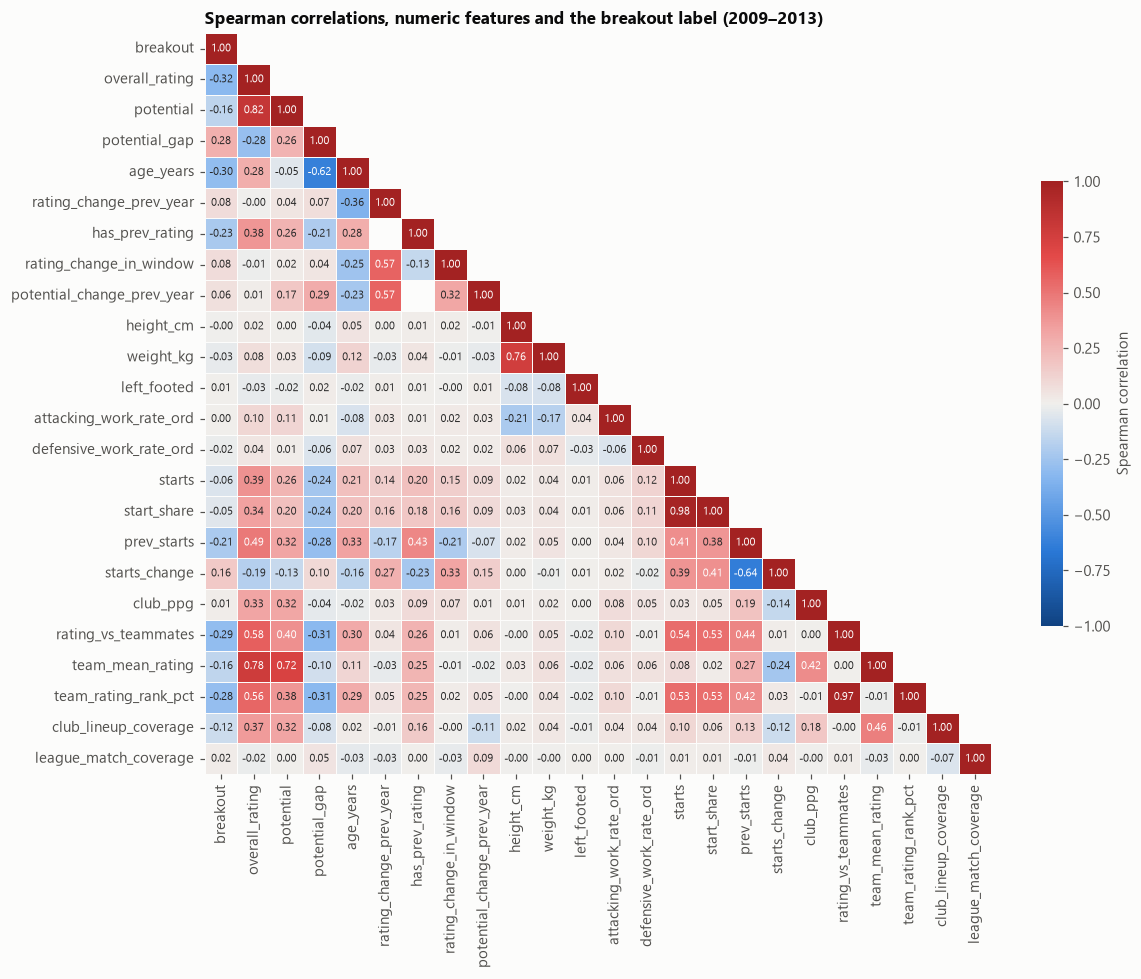

In [13]:
heat_cols = ["breakout", "overall_rating", "potential", "potential_gap", "age_years",
             "rating_change_prev_year", "has_prev_rating", "rating_change_in_window",
             "potential_change_prev_year", "height_cm", "weight_kg", "left_footed",
             "attacking_work_rate_ord", "defensive_work_rate_ord", "starts", "start_share", "prev_starts",
             "starts_change", "club_ppg", "rating_vs_teammates", "team_mean_rating",
             "team_rating_rank_pct", "club_lineup_coverage", "league_match_coverage"]
corr = dev[heat_cols].corr(method="spearman")
save(corr.reset_index().rename(columns={"index": "feature"}), A_TABLES, "feature_correlations_spearman")
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=diverging_cmap(), vmin=-1, vmax=1, center=0, annot=True,
            fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor=COLORS["surface"],
            cbar_kws={"shrink": 0.6, "label": "Spearman correlation"}, ax=ax)
ax.set_title("Spearman correlations, numeric features and the breakout label (2009–2013)")
ax.grid(False)
fig.tight_layout()
save(fig, A_FIGURES, "04_feature_correlation_heatmap");

In [14]:
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs[(pairs.a != "breakout") & (pairs.b != "breakout")]
pairs.reindex(pairs.rho.abs().sort_values(ascending=False).index).head(12).round(3)

,a,b,rho
351,starts,start_share,0.982
477,rating_vs_teammates,team_rating_rank_pct,0.972
26,overall_rating,potential,0.825
44,overall_rating,team_mean_rating,0.777
226,height_cm,weight_kg,0.764
68,potential,team_mean_rating,0.721
401,prev_starts,starts_change,-0.639
76,potential_gap,age_years,-0.620
43,overall_rating,rating_vs_teammates,0.582
127,rating_change_prev_year,rating_change_in_window,0.568


Notable structure: `overall_rating`, `rating_vs_teammates` and `team_rating_rank_pct` are strongly
related (a good player is high in his squad); `potential_gap` is strongly negatively related to age;
`starts`, `start_share` and `prev_starts` move together. Redundant pairs are not a problem for tree
models, but they make logistic-regression coefficients unstable, so coefficients will be read with
care (workstream 4) and regularisation is used.

## 6. Skill redundancy and PCA

skill pairs with |r| > 0.8: 24 of 1089


gk_handling      gk_positioning     0.976
gk_positioning   gk_reflexes        0.976
gk_handling      gk_reflexes        0.975
marking          standing_tackle    0.953
standing_tackle  sliding_tackle     0.953
marking          sliding_tackle     0.935
gk_diving        gk_reflexes        0.913
acceleration     sprint_speed       0.905
dtype: float64

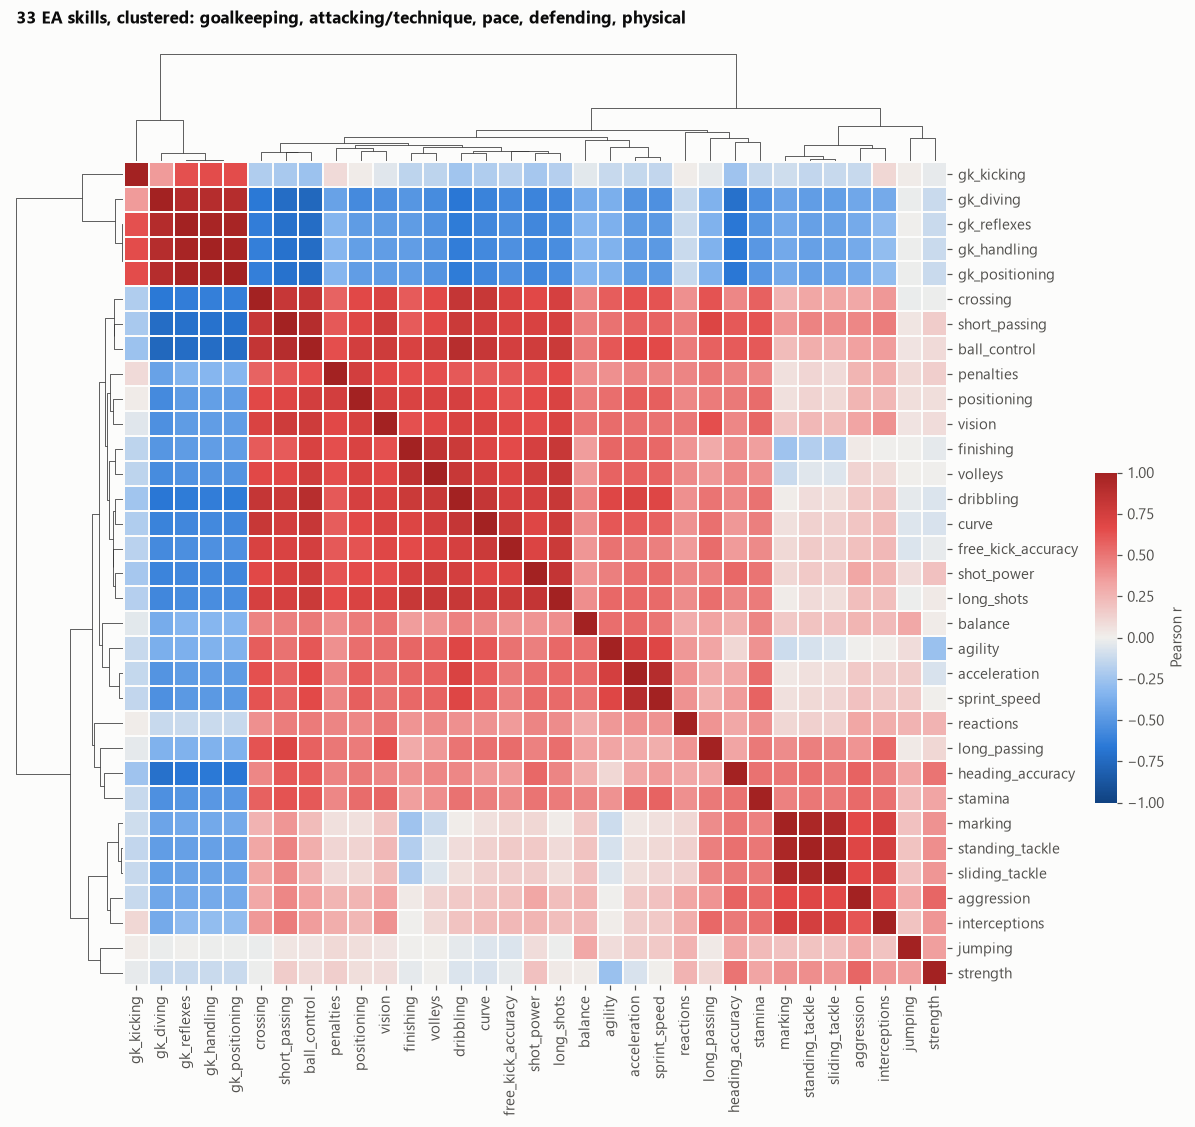

In [15]:
skill_corr = dev[SKILLS].corr()
save(skill_corr.reset_index().rename(columns={"index": "skill"}), A_TABLES, "skill_correlations")
g = sns.clustermap(skill_corr, cmap=diverging_cmap(), vmin=-1, vmax=1, center=0,
                   figsize=(10, 10), linewidths=0.3, linecolor=COLORS["surface"],
                   cbar_kws={"label": "Pearson r"}, dendrogram_ratio=0.12,
                   cbar_pos=(1.0, 0.3, 0.02, 0.3))
g.fig.suptitle("33 EA skills, clustered: goalkeeping, attacking/technique, pace, defending, physical",
               x=0.02, y=1.02, ha="left", fontsize=11, fontweight="bold")
save(g.fig, A_FIGURES, "05_skill_correlation_clustermap")
upper = skill_corr.where(np.triu(np.ones_like(skill_corr, dtype=bool), k=1)).stack()
print(f"skill pairs with |r| > 0.8: {(upper.abs() > 0.8).sum()} of {len(upper)}")
upper.abs().sort_values(ascending=False).head(8).round(3)

components for 80% / 90% of skill variance: 6 / 12


,component,explained,cumulative
0,1,0.471,0.471
1,2,0.154,0.626
2,3,0.079,0.705
3,4,0.048,0.753
4,5,0.045,0.798
5,6,0.025,0.823
6,7,0.022,0.845
7,8,0.015,0.860


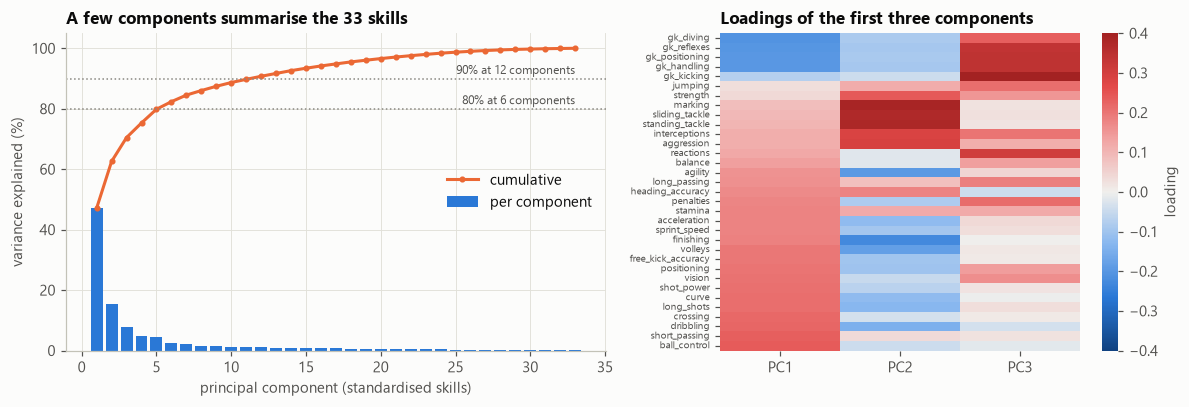

In [16]:
evr, loadings = E.skill_pca(dev)
cum = np.cumsum(evr)
pca_table = pd.DataFrame({"component": np.arange(1, len(evr) + 1), "explained": evr, "cumulative": cum})
save(pca_table, A_TABLES, "skill_pca_explained_variance")
save(loadings.iloc[:, :5].reset_index().rename(columns={"index": "skill"}), A_TABLES, "skill_pca_loadings")
k80, k90 = int(np.searchsorted(cum, 0.8) + 1), int(np.searchsorted(cum, 0.9) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ax.bar(pca_table.component, 100 * evr, color=COLORS["all"], width=0.8, label="per component")
ax.plot(pca_table.component, 100 * cum, color=COLORS["young"], marker="o", markersize=3, linewidth=2, label="cumulative")
for k, p in [(k80, 80), (k90, 90)]:
    ax.axhline(p, color=COLORS["muted"], linestyle=":", linewidth=1)
    ax.text(len(evr), p + 1.5, f"{p}% at {k} components", ha="right", fontsize=8, color=COLORS["ink2"])
ax.set_xlabel("principal component (standardised skills)")
ax.set_ylabel("variance explained (%)")
ax.set_title("A few components summarise the 33 skills")
ax.legend(loc="center right")
ax = axes[1]
top = loadings.iloc[:, :3]
sns.heatmap(top.loc[top.PC1.sort_values().index], cmap=diverging_cmap(), center=0, vmin=-0.4, vmax=0.4,
            ax=ax, cbar_kws={"label": "loading"}, yticklabels=True)
ax.tick_params(axis="y", labelsize=6.5)
ax.set_title("Loadings of the first three components")
ax.grid(False)
fig.tight_layout()
save(fig, A_FIGURES, "07_skill_pca");
print(f"components for 80% / 90% of skill variance: {k80} / {k90}")
pca_table.head(8).round(3)

The skills are highly redundant (goalkeeping skills with each other, marking/standing/sliding tackle,
the attacking/technique block). PC1 is roughly "outfield vs goalkeeper", PC2 "defender vs attacker", and
PC3 mixes goalkeeping with strength, jumping and reactions. PCA is therefore offered as an **option** in `make_preprocessor(pca_skills=k)`
for the linear model; tree models get the raw skills. PCA is fitted inside the pipeline on training
rows only (the PCA above is exploratory, on all development rows, and is not used for modelling).

## 7. Quick feature-group screening on the validation folds

Not model selection (that is workstream 3). Two fixed, untuned models — scaled L2 logistic
regression and default histogram gradient boosting — are trained on earlier years and scored on
2011, 2012 and 2013, to check that each group adds signal before it enters a feature set.

In [17]:
S = F.FEATURE_SETS
body = ["height_cm", "weight_kg", "left_footed", "attacking_work_rate_ord", "defensive_work_rate_ord"]
hist = ["rating_change_prev_year", "has_prev_rating", "rating_change_in_window", "potential_change_prev_year"]
new_match = ["prev_starts", "starts_change", "has_prev_season", "team_mean_rating", "team_rating_rank_pct",
             "club_lineup_coverage", "league_match_coverage"]
variants = {
    "ea_gap_only": S["ea_gap_only"],
    "gap_plus_age": ["potential_gap", "age_years"],
    "rating_no_potential": S["rating_no_potential"],
    "rating_only": S["rating_only"],
    "rating_only − history": [c for c in S["rating_only"] if c not in hist],
    "rating_only − body/foot/work": [c for c in S["rating_only"] if c not in body],
    "combined": S["combined"],
    "combined − new match feats": [c for c in S["combined"] if c not in new_match],
    "combined − coverage flags": [c for c in S["combined"] if c not in ["club_lineup_coverage", "league_match_coverage"]],
    "combined + excluded calendar feats": S["combined"] + F.EXCLUDED_ENGINEERED,
}
screen = pd.concat([E.screen_feature_groups(dev, variants, c) for c in ["all", "young"]])
save(screen, A_TABLES, "feature_group_screening")
summary = (screen.groupby(["cohort", "variant", "model"], sort=False)
           [["precision_at_10pct", "average_precision"]].mean().unstack("model").round(3))
flat = summary.reset_index()
flat.columns = ["_".join(c).strip("_") for c in flat.columns]
save(flat, A_TABLES, "feature_group_screening_summary")
summary

precision_at_10pct        average_precision       
model                                               logistic    hgb          logistic    hgb
cohort variant                                                                              
all    ea_gap_only                                     0.413  0.413             0.343  0.341
       gap_plus_age                                    0.453  0.436             0.382  0.355
       rating_no_potential                             0.440  0.471             0.375  0.389
       rating_only                                     0.440  0.447             0.380  0.388
       rating_only − history                           0.441  0.469             0.380  0.389
       rating_only − body/foot/work                    0.427  0.455             0.377  0.391
       combined                                        0.518  0.541             0.448  0.459
       combined − new match feats                      0.505  0.518             0.442  0.447
       combined − coverage flags                       0.512  0.534             0.450  0.457
       combined + excluded calendar feats              0.504  0.541             0.438  0.456
young  ea_gap_only                                     0.543  0.543             0.424  0.414
       gap_plus_age                                    0.555  0.487             0.456  0.398
       rating_no_potential                             0.559  0.582             0.456  0.454
       rating_only                                     0.573  0.568             0.460  0.453
       rating_only − history                           0.571  0.561             0.461  0.454
       rating_only − body/foot/work                    0.561  0.547             0.456  0.447
       combined                                        0.650  0.650             0.533  0.524
       combined − new match feats                      0.632  0.641             0.529  0.518
       combined − coverage flags                       0.641  0.660             0.535  0.522
       combined + excluded calendar feats              0.636  0.648             0.521  0.528

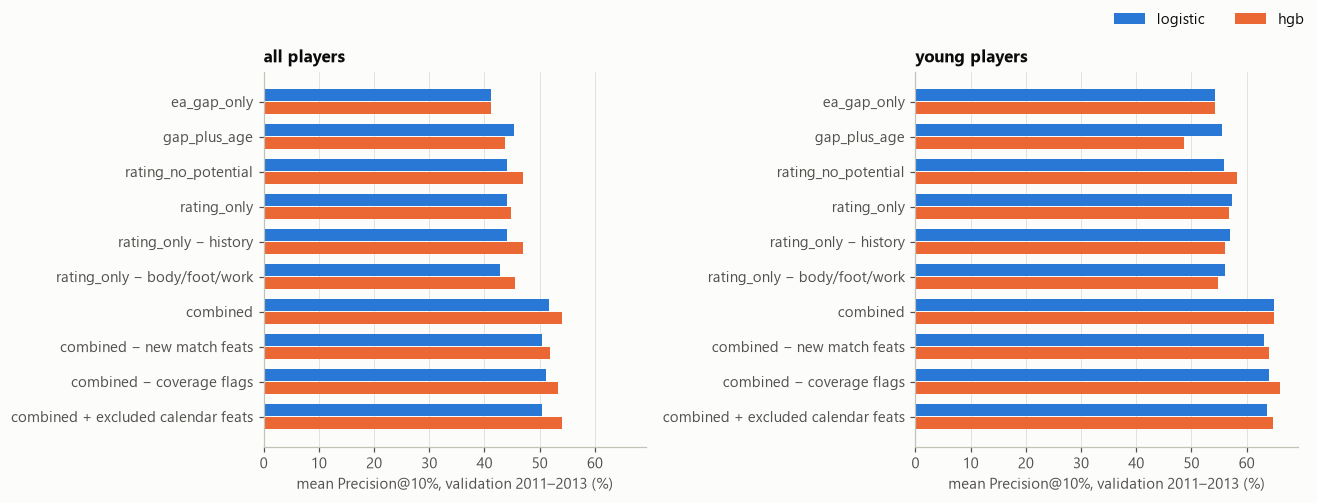

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=True)
for ax, name in zip(axes, ["all", "young"]):
    s = screen[screen.cohort == name].groupby(["variant", "model"], sort=False).precision_at_10pct.mean().unstack()
    y = np.arange(len(s))
    for i, (m, color) in enumerate([("logistic", COLORS["all"]), ("hgb", COLORS["young"])]):
        ax.barh(y + (i - 0.5) * 0.38, 100 * s[m], height=0.36, color=color, label=m)
    ax.set_yticks(y, s.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
    ax.set_xlabel("mean Precision@10%, validation 2011–2013 (%)")
    ax.set_title(f"{name} players")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, A_FIGURES, "08_feature_group_screening");

What the screening says (mean Precision@10% over 2011–2013; exact numbers in
`tables/feature_group_screening_summary.csv`):

* **Potential adds little once rating, skills and age are in.** `rating_no_potential` and
  `rating_only` are within 1–2 points of each other in both cohorts, with no consistent direction. This is the key fact for
  the circularity concern: the models do not depend on EA's subjective potential.
* **Age alone recovers part of EA's gap advantage**: logistic regression on gap + age beats the gap.
* **Match history adds the most**: `combined` is about 6–10 points above `rating_only`. Adding
  `starts` or `start_share` alone to `rating_only` gives most of that gain; the newly engineered
  match features add about one more point.
* Rating history and body/foot/work-rate features each add 0–1.5 points; they stay in (cheap,
  no leakage risk), but they are not where the signal is.
* The excluded calendar features (`n_rating_updates_1y`, `rating_age_days`) add nothing.
* The coverage flags change results by less than one point either way. We keep
  `club_lineup_coverage` (it tells a model when `starts` is undercounted) and drop
  `league_match_coverage`, which is constant in four of the five development years.
* With about 3,700 rows (370 watch-list places) per validation year, differences of 1–2 points
  are within noise; only the match-history gain is clearly larger than that.

## 8. Encoding and scaling (what `make_preprocessor` does)

* **Imputation:** median for numeric columns (robust to the skewed counts and to the few skill
  gaps); missingness that carries information is kept as explicit flags (`has_prev_rating`,
  `has_prev_season`) rather than relying on the imputed value.
* **Scaling:** standardisation only for linear models (`scale=True`); trees are invariant to
  monotone transforms, so they get `scale=False`.
* **Categoricals:** `league` and `position` are one-hot encoded; a missing position becomes an
  explicit `Unknown` level (≈ Poland, see §2); categories unseen in training are ignored.
* **Work rates** are ordinal (low < medium < high) and encoded 0/1/2 as a single numeric column.
* **PCA (optional):** median-impute → standardise → PCA on the skill columns only.
* Everything is fitted **inside the model pipeline on the training rows of each fold**, never on
  validation or test rows.

In [19]:
for name, cols in F.FEATURE_SETS.items():
    print(f"{name:22s} {len(cols):3d} columns ({sum(c in F.CATEGORICAL for c in cols)} categorical)")
pre = F.make_preprocessor(F.FEATURE_SETS["combined"], scale=True, pca_skills=k80)
pre.fit(dev[dev.year < 2011][F.FEATURE_SETS["combined"]])          # e.g. first fold's training rows
print("combined + PCA →", len(pre.get_feature_names_out()), "model inputs")
save(pd.Series({k: ", ".join(v) for k, v in F.FEATURE_SETS.items()}).to_frame("columns"),
     A_TABLES, "feature_sets", index=True)

ea_gap_only              1 columns (0 categorical)
rating_no_potential     44 columns (1 categorical)
rating_only             47 columns (1 categorical)
combined                58 columns (2 categorical)
combined + PCA → 45 model inputs


WindowsPath('D:/1.NYU_COURSES/3.DATA_SCIENCE/final_project/A_checkin_1124/tables/feature_sets.csv')